**1. Clone the working branch**

In [1]:
import subprocess
from pathlib import Path

ROOT = Path("/kaggle/working/BioGRAG-QA")
subprocess.run(
    ["git", "clone", "--branch", "GRAG/reproduce/WebQSP",
     "https://github.com/MichaelPham2005/BioGRAG-QA.git", str(ROOT)],
    check=True,
)
print(subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=ROOT, text=True
).strip())

Cloning into '/kaggle/working/BioGRAG-QA'...


3f36aa818d8e3e838545d6fbf4d34f5e6fdc9be8


**2. Create an isolated working environment**

In [2]:
import shutil
import subprocess
import sys
from pathlib import Path

UV = shutil.which("uv")
if UV is None:
    tools = Path("/kaggle/working/grag-tools")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--target", str(tools), "uv"],
        check=True,
    )
    UV = str(tools / "bin" / "uv")
    if not Path(UV).is_file():
        raise FileNotFoundError(f"uv installation did not create {UV}")

subprocess.run([UV, "--version"], check=True)

ENV = Path("/kaggle/working/grag-venv")
PY = str(ENV / "bin/python")
subprocess.run(
    [UV, "venv", "--python", "3.10", str(ENV)],
    check=True,
)

def install(*args):
    subprocess.run(
        [UV, "pip", "install", "--python", PY, *args],
        cwd=ROOT, check=True,
    )

install("torch==2.0.1", "--index-url", "https://download.pytorch.org/whl/cu118")
install("-r", "requirements-kaggle.txt")
install(
    "torch-scatter==2.1.2+pt20cu118",
    "--find-links", "https://data.pyg.org/whl/torch-2.0.1+cu118.html",
    "--only-binary", "torch-scatter",
)
subprocess.run(
    [UV, "pip", "check", "--python", PY], check=True
)

def run(code):
    subprocess.run([PY, "-u", "-c", code], cwd=ROOT, check=True)

uv 0.13.4 (x86_64-unknown-linux-gnu)


Using CPython 3.10.22
Creating virtual environment at: grag-venv
Activate with: source grag-venv/bin/activate
Using Python 3.10.22 environment at: /kaggle/working/grag-venv
Resolved 11 packages in 2.45s
Prepared 11 packages in 28.47s
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 11 packages in 4.06s
 + cmake==3.25.0
 + filelock==4.1.0
 + jinja2==3.1.6
 + lit==15.0.7
 + markupsafe==3.0.3
 + mpmath==1.3.0
 + networkx==3.4.2
 + sympy==1.14.0
 + torch==2.0.1+cu118
 + triton==2.0.0
 + typing-extensions==4.16.0
Using Python 3.10.22 environment at: /kaggle/working/grag-venv
Resolved 80 packages in 19.80s
Prepared 69 packages in 4.12s
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or 

**3. Validate the environment before downloading models**

In [3]:
run("""
import torch, datasets, transformers, peft, gensim
from torch_scatter import scatter
from torch_geometric.nn import GATConv
print("torch:", torch.__version__)
print("CUDA:", torch.version.cuda)
assert torch.cuda.is_available(), "Enable the Kaggle GPU accelerator."
assert torch.cuda.device_count() == 2, "Select T4 x2."
for i in range(2):
    p = torch.cuda.get_device_properties(i)
    print(i, p.name, round(p.total_memory / 2**30, 2), "GiB")
x = torch.ones(3, 2, device="cuda")
batch = torch.tensor([0, 0, 1], device="cuda")
assert scatter(x, batch, dim=0, reduce="mean").shape == (2, 2)
conv = GATConv(4, 4, heads=2, concat=False).cuda()
out = conv(torch.ones(2, 4, device="cuda"),
           torch.tensor([[0, 1], [1, 0]], device="cuda"))
assert out.shape == (2, 4)
print("Imports and basic CUDA graph operations passed.")
""")

torch: 2.0.1+cu118
CUDA: 11.8
0 Tesla T4 14.56 GiB
1 Tesla T4 14.56 GiB
Imports and basic CUDA graph operations passed.


**4. Download and inspect the raw dataset**

In [4]:
run("""
from datasets import load_dataset

ds = load_dataset("rmanluo/RoG-webqsp")
print(ds)
for split, rows in ds.items():
    print(split, len(rows), rows.column_names)
    assert {"question", "answer", "graph"} <= set(rows.column_names)
    assert isinstance(rows[0]["question"], str)
    assert isinstance(rows[0]["answer"], list)
    assert all(len(triple) == 3 for triple in rows[0]["graph"])
ds.save_to_disk("dataset/webqsp/raw")
row = ds["train"][0]
print("question:", row["question"])
print("answer:", row["answer"])
print("first three graph triples:", row["graph"][:3])
""")

Generating test split: 100%|██████████| 1628/1628 [00:02<00:00, 639.86 examples/s]


DatasetDict({
    train: Dataset({
        features: ['id', 'question', 'answer', 'q_entity', 'a_entity', 'graph', 'choices'],
        num_rows: 2826
    })
    validation: Dataset({
        features: ['id', 'question', 'answer', 'q_entity', 'a_entity', 'graph', 'choices'],
        num_rows: 246
    })
    test: Dataset({
        features: ['id', 'question', 'answer', 'q_entity', 'a_entity', 'graph', 'choices'],
        num_rows: 1628
    })
})
train 2826 ['id', 'question', 'answer', 'q_entity', 'a_entity', 'graph', 'choices']
validation 246 ['id', 'question', 'answer', 'q_entity', 'a_entity', 'graph', 'choices']
test 1628 ['id', 'question', 'answer', 'q_entity', 'a_entity', 'graph', 'choices']


Saving the dataset (2/2 shards): 100%|██████████| 1628/1628 [00:00<00:00, 3715.43 examples/s]


question: what is the name of justin bieber brother
answer: ['Jaxon Bieber']
first three graph triples: [['P!nk', 'freebase.valuenotation.is_reviewed', 'Gender'], ['1Club.FM: Power', 'broadcast.content.artist', 'P!nk'], ['Somebody to Love', 'music.recording.contributions', 'm.0rqp4h0']]


**5. Dataset Fingerprinting & Summary**

In [5]:
run("""
import json
from datasets import load_from_disk
ds = load_from_disk("dataset/webqsp/raw")
summary = {s: {"rows": len(d), "fingerprint": d._fingerprint}
           for s, d in ds.items()}
with open("dataset/webqsp/raw/download-summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(summary)
""")

{'train': {'rows': 2826, 'fingerprint': 'fddf22e46cbe3685'}, 'validation': {'rows': 246, 'fingerprint': 'e6e3cc1fe562598e'}, 'test': {'rows': 1628, 'fingerprint': 'b57bed092b735f97'}}


**6. Preprocess in stages**
```mermaid
flowchart LR
    HF["HF question / answer / graph triples"]
    HF --> S1["step_one"] --> O1["nodes/{i}.csv<br/>edges/{i}.csv"]
    HF --> GS["generate_split"] --> O2["split/*_indices.txt"]
    HF --> S2["step_two"] --> O3["q_embs.pt<br/>graphs/{i}.pt"]
    HF --> RP["retrieval preprocess"] --> O4["sims_2hop_none/{i}.pt<br/>cached_graphs/{i}.pt<br/>cached_desc/{i}.txt"]
```

**Stage A: text tables and split indices**

[`step_one`](../../src/dataset/preprocess/webqsp.py#L33) lowercases head/tail entity text, assigns IDs in first-seen order, and saves:

#### `nodes/{i}.csv`

| `node_id` | `node_attr` |
| :--- | :--- |
| `0` | `entity a` |
| `1` | `entity b` |

#### `edges/{i}.csv`

| `src` | `edge_attr` | `dst` |
| :--- | :--- | :--- |
| `0` | `relation.name` | `1` |

In [6]:
run("""
from src.dataset.preprocess.webqsp import step_one, generate_split
step_one()
generate_split()
""")

inherit model weights from sentence-transformers/all-roberta-large-v1


/kaggle/working/grag-venv/lib/python3.10/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/kaggle/working/grag-venv/lib/python3.10/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
100%|██████████| 4700/4700 [03:23<00:00, 23.06it/s]


# train samples:  2826
# val samples:  246
# test samples:  1628


**Chart average nodes/edges per query**

        nodes   edges
split                
test   1385.1  4309.3
train  1363.1  4229.2
val    1365.9  4141.7
all    1370.9  4252.4
        nodes    edges
count  4700.0   4700.0
mean   1370.9   4252.4
std     567.3   2239.0
min       0.0      0.0
25%     880.8   2276.0
50%    1481.0   4281.0
75%    1937.0   5977.0
max    2000.0  10818.0


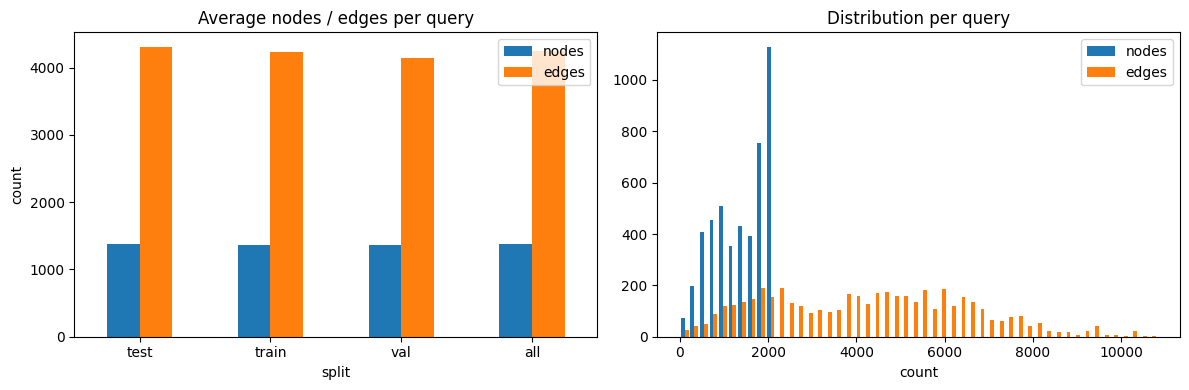

In [7]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

root = str(ROOT / "dataset/webqsp")  # ROOT from the clone cell; notebook cwd is not the repo
n = len(glob.glob(f"{root}/nodes/*.csv"))
split = {}
for name in ["train", "val", "test"]:
    with open(f"{root}/split/{name}_indices.txt") as f:
        for line in f:
            if line.strip():
                split[int(line)] = name

def count(path):
    try:
        return len(pd.read_csv(path))
    except pd.errors.EmptyDataError:
        return 0

df = pd.DataFrame({
    "idx": range(n),
    "nodes": [count(f"{root}/nodes/{i}.csv") for i in range(n)],
    "edges": [count(f"{root}/edges/{i}.csv") for i in range(n)],
})
df["split"] = df["idx"].map(split)

summary = df.groupby("split")[["nodes", "edges"]].mean()
summary.loc["all"] = df[["nodes", "edges"]].mean()
print(summary.round(1))
print(df[["nodes", "edges"]].describe().round(1))

os.makedirs(f"{root}/stats", exist_ok=True)
summary.to_csv(f"{root}/stats/avg_nodes_edges.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
summary.plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Average nodes / edges per query")
axes[0].set_ylabel("count")
axes[1].hist([df["nodes"], df["edges"]], bins=50, label=["nodes", "edges"])
axes[1].set_title("Distribution per query")
axes[1].set_xlabel("count")
axes[1].legend()
plt.tight_layout()
plt.savefig(f"{root}/stats/avg_nodes_edges.png", dpi=150)
plt.show()

**Stage B: check one graph and SentenceBERT before the full embedding job**

These assertions matter because
[sber_text2embedding](../../src/utils/lm_modeling.py#L106) catches errors and
returns an empty tensor instead of raising.

In [8]:
run("""
import pandas as pd
import torch
from src.utils.lm_modeling import load_model, load_text2embedding

nodes = pd.read_csv("dataset/webqsp/nodes/0.csv")
edges = pd.read_csv("dataset/webqsp/edges/0.csv")
model, tokenizer, device = load_model["sbert"]()
encode = load_text2embedding["sbert"]
texts = nodes.node_attr.fillna("").head(3).tolist()
x = encode(model, tokenizer, device, texts)
assert x.shape == (len(texts), 1024), x.shape
assert torch.isfinite(x).all()
assert torch.allclose(x.norm(dim=1), torch.ones(len(texts)), atol=1e-4)
assert edges[["src", "dst"]].to_numpy().min() >= 0
assert edges[["src", "dst"]].to_numpy().max() < len(nodes)
print("Text encoding and graph-0 endpoint checks passed:", x.shape)
""")

inherit model weights from sentence-transformers/all-roberta-large-v1


/kaggle/working/grag-venv/lib/python3.10/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/kaggle/working/grag-venv/lib/python3.10/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Text encoding and graph-0 endpoint checks passed: torch.Size([3, 1024])


**Stage C: embed all questions, nodes and edges**

> **Memory Constraint (T4 GPU):** The original embedding batch size is `256`. Here, it is **explicitly reduced to `16` for T4 memory** (in this subprocess only).
> * This only changes execution batching, not the encoder architecture or retrieval settings (though minor floating-point differences remain possible).
> * **Action on OOM:** If it still runs out of memory, stop and lower the embedding batch size further. **Do not** silently accept empty embeddings.

### Output & Encoder Details

[`step_two`](../../src/dataset/preprocess/webqsp.py#L85) uses `sentence-transformers/all-roberta-large-v1` (not Llama) and generates:

* **`q_embs.pt`**: Tensor of shape `[number_of_questions, 1024]`
* **`graphs/{i}.pt`**: Graph objects containing:
  * `x`: `[V, 1024]`
  * `edge_index`: `[2, E]`
  * `edge_attr`: `[E, 1024]`
* **Graph State Note:** Raw graphs do not yet include repeated `question_node` or `question_edge` fields; the retrieval stage adds those later.

> **Baseline Reproducibility Warning:** Preserve the author's original preprocessing when targeting their benchmark results. [`remove_repeated_edges_tensor`](../../src/dataset/preprocess/webqsp.py#L17) removes **all** edges for endpoint pairs occurring more than once—not merely all but one duplicate. Because this alters the graph structure, **do not** silently "correct" this behavior within a baseline run.


In [27]:
import os, subprocess

stale = subprocess.run(["pgrep", "-f", "webqsp_sharded"],
                       capture_output=True, text=True).stdout.split()
if stale:
    raise RuntimeError(f"Workers already running: PIDs {stale}. "
                       "Use the stop cell below first.")

NUM_SHARDS = 2
procs = []
for shard in range(NUM_SHARDS):
    env = {**os.environ, "CUDA_VISIBLE_DEVICES": str(shard)}
    log = open(f"/kaggle/working/embed_shard{shard}.log", "w")
    procs.append(subprocess.Popen(
        [PY, "-u", "-m", "src.dataset.preprocess.webqsp_sharded",
         "--shard", str(shard), "--num_shards", str(NUM_SHARDS),
         "--batch_size", "64", "--fp16"],
        cwd=ROOT, env=env, stdout=log, stderr=subprocess.STDOUT,
    ))
print("launched PIDs:", [p.pid for p in procs])

launched PIDs: [565, 566]


In [ ]:
import re, time
from pathlib import Path

total = 4700
graphs = Path(ROOT) / "dataset/webqsp/graphs"
while True:
    codes = [p.poll() for p in procs]
    done = len(list(graphs.glob("*.pt")))
    gpu = subprocess.run(
        ["nvidia-smi", "--query-gpu=utilization.gpu,memory.used",
         "--format=csv,noheader"], capture_output=True, text=True).stdout.split("\n")
    last = []
    for s in range(NUM_SHARDS):
        txt = open(f"/kaggle/working/embed_shard{s}.log", errors="replace").read()
        bars = re.findall(r"shard \d+:[^\r\n]*", txt.replace("\r", "\n"))
        last.append(bars[-1] if bars else "(no progress yet)")
    print(time.strftime("%H:%M:%S"), f"graphs {done}/{total}", "exit:", codes)
    for s, l in enumerate(last):
        print(f"  {l}   GPU: {gpu[s].strip()}")
    if any(c not in (None, 0) for c in codes):
        raise RuntimeError("A worker failed; read /kaggle/working/embed_shard*.log")
    if all(c == 0 for c in codes):
        break
    time.sleep(30)
print("all workers finished")

**Validate every generated graph before retrieval**

In [10]:
run("""
from pathlib import Path
import torch
from datasets import load_from_disk

ds = load_from_disk("dataset/webqsp/raw")
count = sum(len(d) for d in ds.values())
q = torch.load("dataset/webqsp/q_embs.pt", map_location="cpu")
assert q.shape == (count, 1024), q.shape
assert torch.isfinite(q).all()
root = Path("dataset/webqsp/graphs")
assert len(list(root.glob("*.pt"))) == count
for i in range(count):
    g = torch.load(root / f"{i}.pt", map_location="cpu")
    assert g.x.shape == (g.num_nodes, 1024), i
    assert g.edge_index.shape[0] == 2, i
    assert g.edge_attr.shape == (g.edge_index.shape[1], 1024), i
    assert torch.isfinite(g.x).all() and torch.isfinite(g.edge_attr).all(), i
    if g.edge_index.numel():
        assert int(g.edge_index.min()) >= 0, i
        assert int(g.edge_index.max()) < g.num_nodes, i
print("Validated", count, "base graphs.")
""")

Traceback (most recent call last):
  File "<string>", line 8, in <module>
  File "/kaggle/working/grag-venv/lib/python3.10/site-packages/torch/serialization.py", line 791, in load
    with _open_file_like(f, 'rb') as opened_file:
  File "/kaggle/working/grag-venv/lib/python3.10/site-packages/torch/serialization.py", line 271, in _open_file_like
    return _open_file(name_or_buffer, mode)
  File "/kaggle/working/grag-venv/lib/python3.10/site-packages/torch/serialization.py", line 252, in __init__
    super().__init__(open(name, mode))
FileNotFoundError: [Errno 2] No such file or directory: 'dataset/webqsp/q_embs.pt'


CalledProcessError: Command '['/kaggle/working/grag-venv/bin/python', '-u', '-c', '\nfrom pathlib import Path\nimport torch\nfrom datasets import load_from_disk\n\nds = load_from_disk("dataset/webqsp/raw")\ncount = sum(len(d) for d in ds.values())\nq = torch.load("dataset/webqsp/q_embs.pt", map_location="cpu")\nassert q.shape == (count, 1024), q.shape\nassert torch.isfinite(q).all()\nroot = Path("dataset/webqsp/graphs")\nassert len(list(root.glob("*.pt"))) == count\nfor i in range(count):\n    g = torch.load(root / f"{i}.pt", map_location="cpu")\n    assert g.x.shape == (g.num_nodes, 1024), i\n    assert g.edge_index.shape[0] == 2, i\n    assert g.edge_attr.shape == (g.edge_index.shape[1], 1024), i\n    assert torch.isfinite(g.x).all() and torch.isfinite(g.edge_attr).all(), i\n    if g.edge_index.numel():\n        assert int(g.edge_index.min()) >= 0, i\n        assert int(g.edge_index.max()) < g.num_nodes, i\nprint("Validated", count, "base graphs.")\n']' returned non-zero exit status 

**Stage D: retrieve query-specific ego-graphs**

In [ ]:
subprocess.run(
    [PY, "-u", "-m", "src.dataset.webqsp"], cwd=ROOT, check=True
)

**Stage E: validate training inputs**

In [ ]:
run("""
import torch
from src.dataset.webqsp import WebQSPDataset

ds = WebQSPDataset()
split = ds.get_idx_split()
ids = [i for name in ("train", "val", "test") for i in split[name]]
assert sorted(ids) == list(range(len(ds))), "Splits must partition all samples."
for i in range(len(ds)):
    s = ds[i]
    g = s["graph"]
    assert g.x.shape == (g.num_nodes, 1024), i
    assert g.edge_attr.shape == (g.edge_index.shape[1], 1024), i
    assert g.question_node.shape == g.x.shape, i
    assert g.question_edge.shape == g.edge_attr.shape, i
    for t in (g.x, g.edge_attr, g.question_node, g.question_edge):
        assert torch.isfinite(t).all(), i
    if g.edge_index.numel():
        assert int(g.edge_index.min()) >= 0, i
        assert int(g.edge_index.max()) < g.num_nodes, i
    assert isinstance(s["desc"], str) and s["desc"].strip(), i
    assert isinstance(s["label"], str) and s["label"].strip(), i
print("Validated", len(ds), "cached training samples.")
print({k: len(v) for k, v in split.items()})
""")

**7. Preserve data across Kaggle sessions**

In [ ]:
with open("/kaggle/working/grag-environment.txt", "w") as f:
    subprocess.run(
        [UV, "pip", "freeze", "--python", PY],
        stdout=f, check=True,
    )